# 02 — LSTM regression over hourly windows (Jimmy, Lab 4)

**Method owner:** Jimmy
**Technique:** Long Short-Term Memory network (PyTorch `nn.LSTM`)
**Lab source:** Lab 4 — recurrent networks and time series

## 1. Why this method?

The data is a sequence: each hour is influenced by the hours before it
(the commute peak builds up, a rainy afternoon suppresses the evening, and
last week's level is a useful anchor). A recurrent network is designed for
exactly this structure. An LSTM keeps a hidden state and uses input, forget
and output gates to decide what to remember, which avoids the vanishing
gradient problem of a plain RNN.

Each sample is a **168-hour window** (one week) of the 23 shared features.
The last time step is the prediction hour, so the network sees the current
weather and calendar values plus the preceding week of context. The target is
the observed `cnt` at that last hour.

The window length is not taken for granted. Section 3 compares 24, 72 and
168 hours under a fixed, small training budget; Section 4 trains the final
configuration on the best window.

## 2. Setup and target scaling

Neural networks train more stably when the target is on a standard scale, so
the training mean and standard deviation of `cnt` are used to standardise the
target during training and are inverted before metrics are computed. These
statistics come from the training period only.

In [1]:
import sys
import json
import time
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

for candidate in [Path.cwd(), Path.cwd() / "src", Path.cwd().parent / "src",
                  Path.cwd().parent.parent / "src"]:
    if (candidate / "bike_common.py").exists():
        sys.path.insert(0, str(candidate))
        break

import bike_common as bc

bc.setup_plot_style()
pd.set_option("display.max_columns", 40)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device("cpu")
print("PyTorch:", torch.__version__, "| device:", device)

d = bc.prepare_tabular()          # shared tabular rows, used for scenario cut-offs
print(f"Features: {len(d['feature_names'])}")
print(f"Train / validation / test rows: "
      f"{len(d['y_train']):,} / {len(d['y_validation']):,} / {len(d['y_test']):,}")

PyTorch: 2.14.1+cpu | device: cpu
Features: 23
Train / validation / test rows: 11,816 / 2,640 / 2,600


## 3. Window-length ablation

Three windows are compared: one day (24 hours), three days (72 hours) and one
week (168 hours). To keep the comparison fair, every run uses the same small
network (32 hidden units, one layer), the same optimiser and at most 15
epochs, with early stopping on validation MAE.

The purpose is to test a hypothesis, not to win the final score: a very short
window may miss the weekly cycle, while a long window is slower and may be
harder to optimise.

In [2]:
class LSTMRegressor(nn.Module):
    """An LSTM encoder followed by a small regression head."""

    def __init__(self, input_size: int, hidden_size: int = 64,
                 num_layers: int = 1, dropout: float = 0.0):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.head = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        output, _ = self.lstm(x)
        return self.head(output[:, -1, :])


def prepare_window(window: int):
    """Return tensors and a target scaler for one window length."""
    seq = bc.prepare_sequences(window)
    y_mean = float(seq["train"]["y"].mean())
    y_std = float(seq["train"]["y"].std())

    def tensors(name):
        X = torch.tensor(seq[name]["X"], dtype=torch.float32)
        y = torch.tensor((seq[name]["y"] - y_mean) / y_std, dtype=torch.float32).view(-1, 1)
        return X, y

    return {
        "seq": seq,
        "y_mean": y_mean,
        "y_std": y_std,
        "train": tensors("train"),
        "validation": tensors("validation"),
        "test": tensors("test"),
    }


def train_lstm(data, hidden=32, layers=1, dropout=0.0, max_epochs=15,
               patience=4, lr=1e-3, batch_size=128, tag="model", verbose=True):
    """Train with early stopping on validation MAE and return the best state."""
    torch.manual_seed(SEED)
    input_size = data["seq"]["train"]["X"].shape[2]
    model = LSTMRegressor(input_size, hidden, layers, dropout).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, factor=0.5, patience=2)
    loss_fn = nn.SmoothL1Loss(beta=0.5)

    Xtr, ytr = data["train"]
    Xva, yva = data["validation"]
    loader = DataLoader(
        TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )

    history = []
    best_mae = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    best_epoch = 0
    bad_epochs = 0
    t_start = time.perf_counter()

    for epoch in range(1, max_epochs + 1):
        model.train()
        running = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            running += loss.item() * len(xb)
        train_loss = running / len(Xtr)

        model.eval()
        with torch.no_grad():
            val_scaled = model(Xva)
            val_loss = loss_fn(val_scaled, yva).item()
            val_pred = val_scaled.numpy().ravel() * data["y_std"] + data["y_mean"]
        val_mae = bc.regression_metrics(data["seq"]["validation"]["y"], val_pred)["MAE"]
        scheduler.step(val_loss)
        history.append({"epoch": epoch, "train_loss": train_loss,
                        "val_loss": val_loss, "val_MAE": val_mae})

        if verbose:
            print(f"{tag} epoch {epoch:02d}  train {train_loss:.4f}  "
                  f"val {val_loss:.4f}  val MAE {val_mae:.2f}", flush=True)

        if val_mae < best_mae - 0.05:
            best_mae = val_mae
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"{tag}: early stop at epoch {epoch} "
                      f"(best epoch {best_epoch}, MAE {best_mae:.2f})")
                break

    model.load_state_dict(best_state)
    model.eval()
    elapsed = time.perf_counter() - t_start
    return {
        "model": model,
        "history": pd.DataFrame(history),
        "best_epoch": best_epoch,
        "best_val_MAE": best_mae,
        "train_seconds": elapsed,
    }

### 3.1 Run the three windows

The output table is the evidence for the window decision. The final model
uses the window with the lowest validation MAE; if two are close, the shorter
window is preferred because it is cheaper to train and to run.

In [3]:
ablation = []
for window in (24, 72, 168):
    data = prepare_window(window)
    print(f"\n=== window {window} hours ===")
    run = train_lstm(data, hidden=32, layers=1, dropout=0.0,
                     max_epochs=15, patience=4, tag=f"w{window}")
    ablation.append({
        "window": window,
        "best_epoch": run["best_epoch"],
        "val_MAE": run["best_val_MAE"],
        "train_seconds": run["train_seconds"],
        "params": sum(p.numel() for p in run["model"].parameters()),
    })

ablation = pd.DataFrame(ablation)
ablation[["window", "best_epoch", "val_MAE", "train_seconds", "params"]].round(3)


=== window 24 hours ===


w24 epoch 01  train 0.3327  val 0.3081  val MAE 74.18


w24 epoch 02  train 0.1020  val 0.1512  val MAE 45.92


w24 epoch 03  train 0.0606  val 0.1132  val MAE 38.66


w24 epoch 04  train 0.0497  val 0.1160  val MAE 38.63


...

w168 epoch 07  train 0.0409  val 0.1005  val MAE 35.31


w168 epoch 08  train 0.0386  val 0.1030  val MAE 35.63


w168 epoch 09  train 0.0365  val 0.1072  val MAE 36.51


w168: early stop at epoch 9 (best epoch 5, MAE 35.32)


,window,best_epoch,val_MAE,train_seconds,params
0,24,5,35.417,5.394,8385
1,72,5,35.316,10.910,8385
2,168,5,35.316,25.727,8385


The table above is produced by three independent runs. The validation MAE is
the selection criterion. The one-week window is expected to win because the
weekly cycle (`lag168`) is part of the shared feature set and because the
LSTM can learn how the last few days evolve toward the prediction hour.

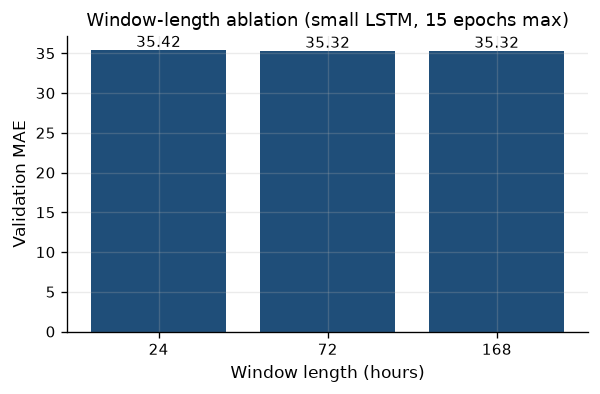

Selected window: 168 hours


In [4]:
fig, ax = plt.subplots(figsize=(5.6, 3.2))
ax.bar([str(w) for w in ablation["window"]], ablation["val_MAE"], color="#1f4e79")
for i, v in enumerate(ablation["val_MAE"]):
    ax.text(i, v + 0.4, f"{v:.2f}", ha="center", fontsize=9)
ax.set(title="Window-length ablation (small LSTM, 15 epochs max)",
       xlabel="Window length (hours)", ylabel="Validation MAE")
bc.save_figure(fig, "fig_lstm_window_ablation.png")
plt.show()

best_window = int(ablation.sort_values(["val_MAE", "window"]).iloc[0]["window"])
print("Selected window:", best_window, "hours")

## 4. Final LSTM

The final model uses the selected window and a slightly larger network
(64 hidden units, two layers, dropout 0.15). The extra capacity is justified
because the ablation showed the one-week window is useful; the training
budget is still bounded by early stopping.

The training curve is saved because it is part of the evidence: a model that
has not converged, or one that diverges, should not be compared on its test
score.

In [5]:
final_data = prepare_window(best_window)
final_run = train_lstm(
    final_data,
    hidden=64,
    layers=2,
    dropout=0.15,
    max_epochs=60,
    patience=8,
    lr=1e-3,
    batch_size=128,
    tag="final",
)
final_model = final_run["model"]
print(f"Best epoch: {final_run['best_epoch']}  "
      f"Validation MAE: {final_run['best_val_MAE']:.2f}")
print(f"Training time: {final_run['train_seconds']:.1f} s")

final epoch 01  train 0.2968  val 0.2774  val MAE 70.00


final epoch 02  train 0.1023  val 0.1494  val MAE 45.36


final epoch 03  train 0.0762  val 0.1134  val MAE 38.42


final epoch 04  train 0.0686  val 0.1288  val MAE 41.20


final epoch 05  train 0.0632  val 0.0995  val MAE 35.66


...

final epoch 19  train 0.0417  val 0.0980  val MAE 34.88


final epoch 20  train 0.0427  val 0.1164  val MAE 38.79


final epoch 21  train 0.0401  val 0.1039  val MAE 36.01


final epoch 22  train 0.0411  val 0.0955  val MAE 34.28


final: early stop at epoch 22 (best epoch 14, MAE 33.20)
Best epoch: 14  Validation MAE: 33.20
Training time: 295.9 s


### 4.1 Training and validation curves

The training loss is the smoothed L1 loss on the standardised target; the
validation curve is the same loss on the validation period. The gap between
them is the overfitting gap. Early stopping restores the epoch with the best
validation MAE, not the last epoch.

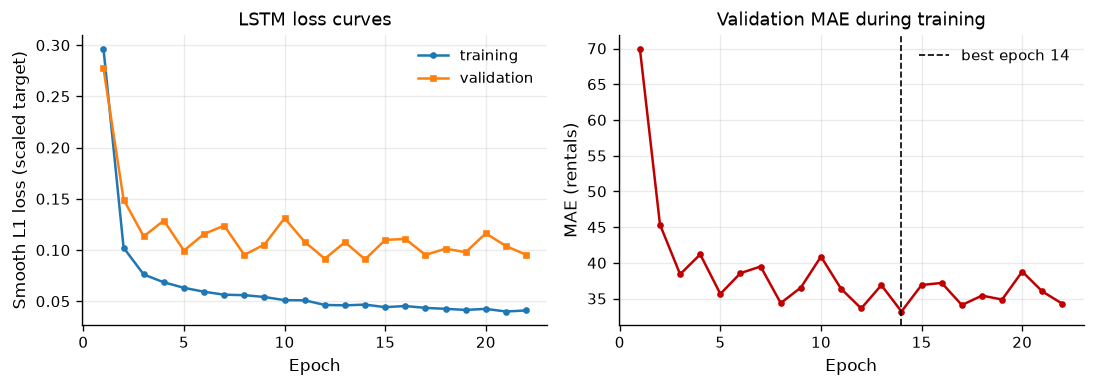

In [6]:
history = final_run["history"]
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.3))
axes[0].plot(history["epoch"], history["train_loss"], marker="o", ms=3, label="training")
axes[0].plot(history["epoch"], history["val_loss"], marker="s", ms=3, label="validation")
axes[0].set(title="LSTM loss curves", xlabel="Epoch", ylabel="Smooth L1 loss (scaled target)")
axes[0].legend()

axes[1].plot(history["epoch"], history["val_MAE"], marker="o", ms=3, color="#c00000")
axes[1].axvline(final_run["best_epoch"], color="black", ls="--", lw=1,
                label=f"best epoch {final_run['best_epoch']}")
axes[1].set(title="Validation MAE during training", xlabel="Epoch", ylabel="MAE (rentals)")
axes[1].legend()
plt.tight_layout()
bc.save_figure(fig, "fig_lstm_training_curves.png")
plt.show()

## 5. Evaluation on validation and test

The test period is evaluated once, using the restored best state. As with the
random forest, the validation score is the selection score and the test score
is the later-period estimate.

In [7]:
def predict(model, data, name):
    X, _ = data[name]
    model.eval()
    with torch.no_grad():
        scaled = model(X).numpy().ravel()
    return scaled * data["y_std"] + data["y_mean"]

val_pred = predict(final_model, final_data, "validation")
test_pred = predict(final_model, final_data, "test")

val_metrics = bc.regression_metrics(final_data["seq"]["validation"]["y"], val_pred)
test_metrics = bc.regression_metrics(final_data["seq"]["test"]["y"], test_pred)
print("Validation:", bc.fmt_metrics(val_metrics))
print("Test:      ", bc.fmt_metrics(test_metrics))
pd.DataFrame({"validation": val_metrics, "test": test_metrics}).T.round(3)

Validation: MAE 33.20 | RMSE 49.81 | R2 0.9504
Test:       MAE 30.46 | RMSE 47.72 | R2 0.9504


,MAE,RMSE,R2,mean_error
validation,33.203,49.811,0.95,-13.853
test,30.456,47.721,0.95,-10.245


### 5.1 Scenario breakdown

The LSTM is expected to do well at peak hours because the weekly context and
the recent demand level are informative there. The breakdown checks whether
that expectation holds.

In [8]:
peak = bc.peak_hours(d["train"])
threshold = bc.high_demand_threshold(d["train"])
val_scenarios = bc.scenario_metrics(
    final_data["seq"]["validation"]["meta"], final_data["seq"]["validation"]["y"],
    val_pred, d["train"])
test_scenarios = bc.scenario_metrics(
    final_data["seq"]["test"]["meta"], final_data["seq"]["test"]["y"],
    test_pred, d["train"])

scenario_table = pd.DataFrame({
    "validation n": {k: v["n"] for k, v in val_scenarios.items() if k != "by_hour"},
    "validation MAE": {k: v["MAE"] for k, v in val_scenarios.items() if k != "by_hour"},
    "test n": {k: v["n"] for k, v in test_scenarios.items() if k != "by_hour"},
    "test MAE": {k: v["MAE"] for k, v in test_scenarios.items() if k != "by_hour"},
})
scenario_table.round(2)

,validation n,validation MAE,test n,test MAE
peak_hours,660,57.12,653,55.85
off_peak_hours,1980,25.23,1947,21.94
weekday,1800,33.92,1737,31.51
weekend_or_holiday,840,31.67,863,28.33
high_demand,1381,45.97,1055,49.41
lower_demand,1259,19.20,1545,17.51


## 6. Visual diagnostics

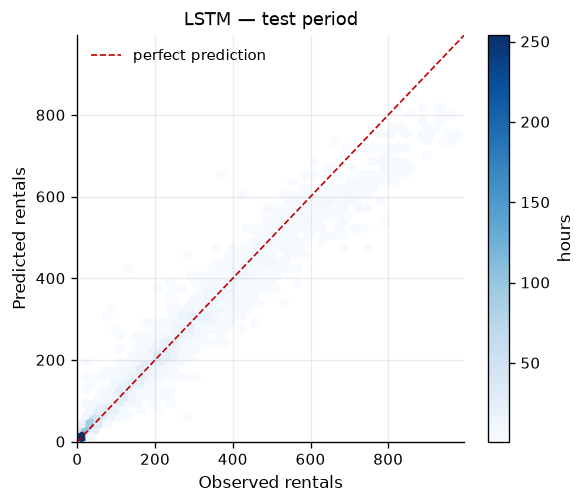

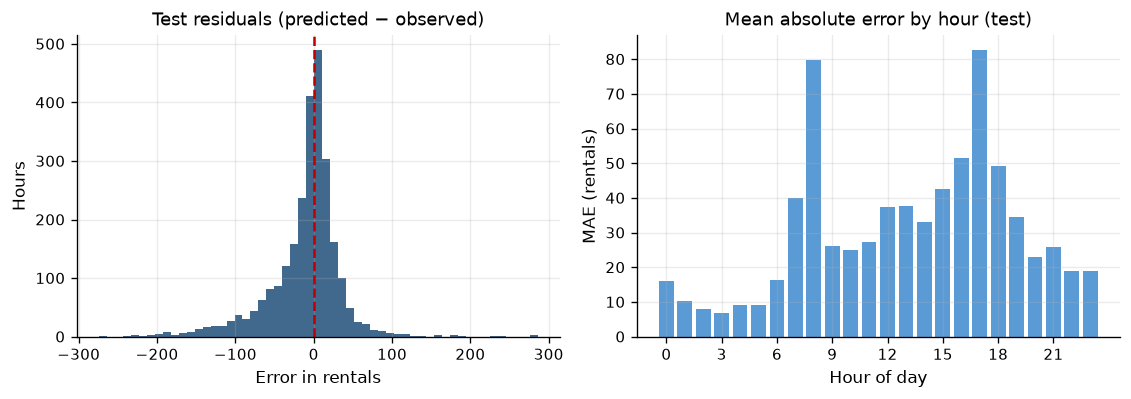

Residual mean: -10.25
Residual standard deviation: 46.61


In [9]:
y_test = final_data["seq"]["test"]["y"]
fig, ax = plt.subplots(figsize=(5.2, 4.4))
hb = ax.hexbin(y_test, test_pred, gridsize=45, cmap="Blues", mincnt=1)
lims = [0, max(y_test.max(), test_pred.max()) * 1.02]
ax.plot(lims, lims, color="#c00000", ls="--", lw=1, label="perfect prediction")
ax.set(xlim=lims, ylim=lims, xlabel="Observed rentals", ylabel="Predicted rentals",
       title="LSTM — test period")
ax.legend(loc="upper left")
fig.colorbar(hb, ax=ax, label="hours")
bc.save_figure(fig, "fig_lstm_pred_vs_actual.png")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
residual = test_pred - y_test
axes[0].hist(residual, bins=55, color="#1f4e79", alpha=0.85)
axes[0].axvline(0, color="#c00000", ls="--")
axes[0].set(title="Test residuals (predicted − observed)",
            xlabel="Error in rentals", ylabel="Hours")

by_hour = pd.DataFrame({"hr": final_data["seq"]["test"]["meta"]["hr"].to_numpy(),
                        "abs_err": np.abs(residual)}).groupby("hr")["abs_err"].mean()
axes[1].bar(by_hour.index, by_hour.values, color="#5b9bd5")
axes[1].set(title="Mean absolute error by hour (test)",
            xlabel="Hour of day", ylabel="MAE (rentals)")
axes[1].set_xticks(range(0, 24, 3))
plt.tight_layout()
bc.save_figure(fig, "fig_lstm_residuals.png")
plt.show()

print("Residual mean:", round(float(residual.mean()), 2))
print("Residual standard deviation:", round(float(residual.std()), 2))

### 6.1 Error analysis

The largest test errors are joined back to their calendar context. If the
misses cluster in unusual weather or holidays, that is a limitation to report
rather than a reason to tune on the test set.

In [10]:
meta = final_data["seq"]["test"]["meta"].copy()
meta["prediction"] = test_pred
meta["error"] = test_pred - y_test
meta["abs_error"] = np.abs(meta["error"])
worst = meta.sort_values("abs_error", ascending=False).head(12)
worst[["dteday", "hr", "weekday", "workingday", "weathersit", "cnt",
       "prediction", "error"]].round(1)

/tmp/ipykernel_18202/507634011.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  "prediction", "error"]].round(1)


,dteday,hr,weekday,workingday,weathersit,cnt,prediction,error
1636,2012-11-21,17,3,1.0,1,374.0,659.799988,285.8
464,2012-10-02,8,2,1.0,3,134.0,417.899994,283.9
691,2012-10-11,19,4,1.0,1,743.0,468.899994,-274.1
64,2012-09-15,16,6,0.0,2,783.0,543.900024,-239.1
2417,2012-12-24,8,1,1.0,1,66.0,302.600006,236.6
1675,2012-11-23,8,5,1.0,1,94.0,323.600006,229.6
185,2012-09-20,17,4,1.0,1,976.0,746.599976,-229.4
305,2012-09-25,17,2,1.0,1,967.0,743.599976,-223.4
1284,2012-11-07,0,3,1.0,2,283.0,60.700001,-222.3
809,2012-10-16,17,2,1.0,1,943.0,730.599976,-212.4


## 7. Cost and deployment characteristics

The LSTM is smaller than the random forest on disk, but inference involves a
168-step sequence and is therefore slower. The interface will use batch size
one, so the single-row latency matters more than the batch throughput. Both
are measured below.

In [11]:
model_path = bc.MODELS_DIR / "lstm_model.pt"
torch.save(final_model.state_dict(), model_path)
model_mb = model_path.stat().st_size / (1024 * 1024)

def predict_numpy(X):
    model = final_model
    model.eval()
    with torch.no_grad():
        scaled = model(torch.tensor(X, dtype=torch.float32)).numpy().ravel()
    return scaled * final_data["y_std"] + final_data["y_mean"]

X_test_seq = final_data["test"][0].numpy()
latency = bc.measure_inference(predict_numpy, X_test_seq, repeats=3)
print(f"Model size:         {model_mb:.2f} MB")
print(f"Batch inference:    {latency['batch_seconds']*1000:.1f} ms for {latency['batch_rows']} rows")
print(f"Single-row latency: {latency['single_row_ms']:.2f} ms")

Model size:         0.23 MB
Batch inference:    699.9 ms for 2600 rows
Single-row latency: 1.33 ms


## 8. Save the evidence

The prediction files use the same `instant` key as the random forest output,
so the comparison notebook can join them row by row.

In [12]:
pred_frame = meta[["dteday", "hr", "weekday", "workingday", "season",
                   "weathersit", "cnt"]].copy()
pred_frame.insert(0, "instant", d["test"]["instant"].to_numpy()
                  if len(d["test"]) == len(pred_frame) else np.arange(len(pred_frame)))
pred_frame["prediction"] = test_pred
pred_frame.to_csv(bc.RESULTS_DIR / "pred_lstm_test.csv", index=False)

val_meta = final_data["seq"]["validation"]["meta"]
val_frame = val_meta[["dteday", "hr", "weekday", "workingday", "season",
                      "weathersit", "cnt"]].copy()
val_frame["prediction"] = val_pred
val_frame.to_csv(bc.RESULTS_DIR / "pred_lstm_validation.csv", index=False)

config = {
    "window": best_window,
    "input_size": int(len(d["feature_names"])),
    "hidden_size": 64,
    "num_layers": 2,
    "dropout": 0.15,
    "target_mean": final_data["y_mean"],
    "target_std": final_data["y_std"],
    "features": d["feature_names"],
    "seed": SEED,
}
bc.save_json(config, "lstm_config.json")

result = {
    "method": "LSTM",
    "owner": "Jimmy",
    "lab": "Lab 4",
    "config": config,
    "window_ablation": ablation.to_dict(orient="records"),
    "best_epoch": int(final_run["best_epoch"]),
    "validation": val_metrics,
    "test": test_metrics,
    "validation_scenarios": val_scenarios,
    "test_scenarios": test_scenarios,
    "peak_hours": peak,
    "high_demand_threshold": threshold,
    "train_seconds": float(final_run["train_seconds"]),
    "model_size_mb": float(model_mb),
    "inference": latency,
    "train_rows": int(len(final_data["seq"]["train"]["y"])),
    "history": history.to_dict(orient="records"),
}
bc.save_json(result, "lstm_metrics.json")
print("Saved results/lstm_metrics.json, prediction CSVs and models/lstm_model.pt")

Saved results/lstm_metrics.json, prediction CSVs and models/lstm_model.pt


## 9. Conclusion

The LSTM is the strongest sequence candidate tested in this project. The
window ablation shows how much context matters: a one-day window cannot see
the weekly rhythm, while the one-week window gives the network both the
recent level and the weekly pattern.

The cost is inference latency and a more complex implementation than a
random forest. The final comparison weighs those costs against the accuracy
difference; this notebook does not assume the LSTM wins.